In [ ]:
import pandas as pd
import plotly.express as px
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

import matplotlib.pyplot as plt



df = pd.read_csv("spiff_data-2.csv")



In [2]:
summary_stats = df.describe()
summary_stats

,Unnamed: 0,day,gurkor,guitars,slingshots,stocks,sugar,water,tranquillity
count,5456.000000,5456.000000,5206.000000,5206.000000,5206.000000,5206.000000,5206.000000,5206.000000,5206.000000
mean,2727.500000,2728.500000,9.886550,6.713898,4.519504,7.309093,3.621403,6.749451,12.502258
std,1575.155865,1575.155865,30.785709,30.850516,30.883866,30.856220,30.904930,30.825744,30.774131
min,0.000000,1.000000,5.942896,2.629048,2.001362,4.012346,1.370262,3.739412,6.614749
25%,1363.750000,1364.750000,6.948963,4.258847,2.808930,4.917271,1.999489,4.996764,9.194215
50%,2727.500000,2728.500000,8.907936,5.912364,3.384898,5.521318,2.606234,5.775716,10.591227
75%,4091.250000,4092.250000,10.191398,7.058370,4.294821,6.977501,3.281805,6.492295,13.382072
max,5455.000000,5456.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000


In [3]:
#sorting on gurkor reveals all have same index, easy to deal with, assume outliers.
df_sort = df.dropna().sort_values(by=df.columns[2], ascending=False).head(8)
df_sort

,Unnamed: 0,day,gurkor,guitars,slingshots,stocks,sugar,water,tranquillity
4117,4117,4118,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
3429,3429,3430,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
1193,1193,1194,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
2835,2835,2836,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
35,35,36,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
5233,5233,5234,14.132395,7.761326,6.077001,6.397775,2.845756,8.949187,11.513032
5232,5232,5233,14.130742,7.718505,5.976410,6.338753,2.870683,8.913880,11.889701
5230,5230,5231,14.112567,7.710233,6.096471,6.217539,2.893532,8.923620,12.051812


In [4]:
df = df.drop([35, 1193, 2835, 3429, 4117], errors='ignore')


## Task 1

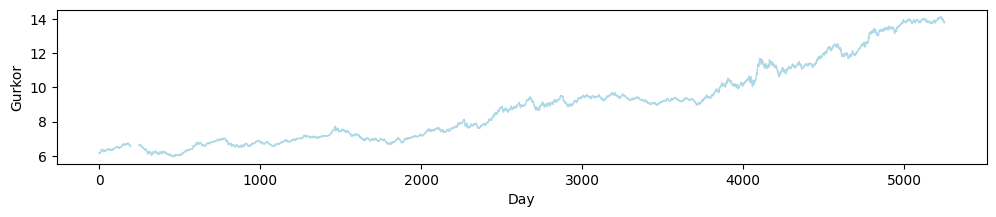

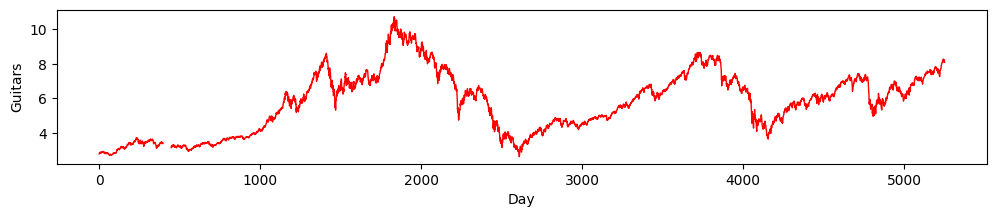

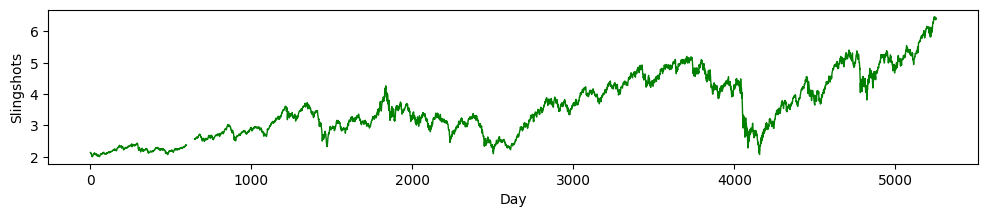

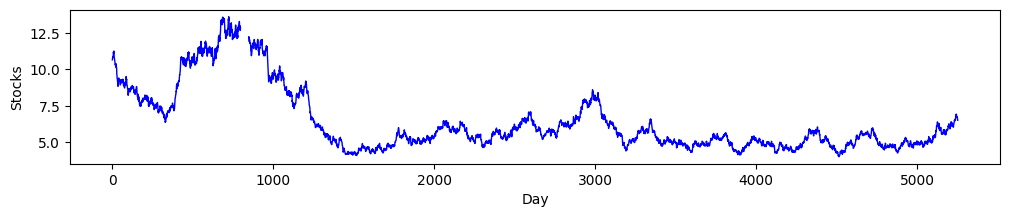

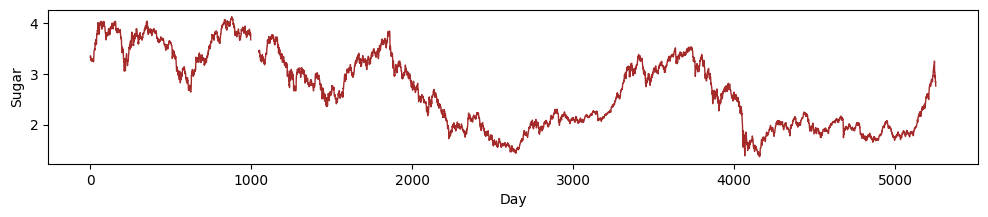

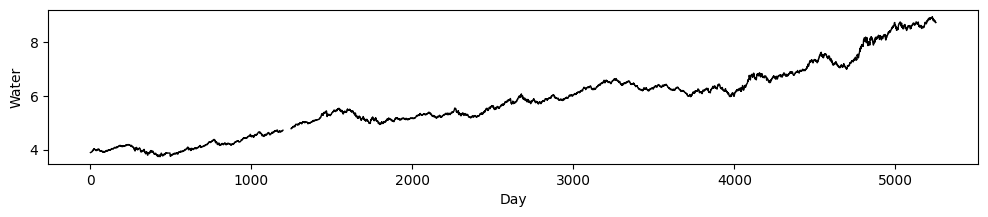

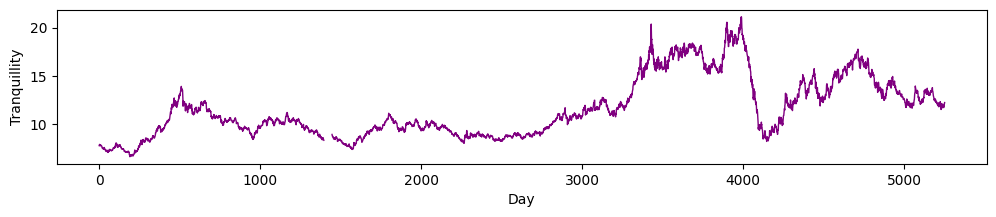

In [5]:
#gurkor plot
import matplotlib.pyplot as plt
import numpy as np

days = df["day"].count()
x_vals_full = np.linspace(1, days, days)
nan_mask = np.isnan(df["gurkor"][0:300])

fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["gurkor"], label='Gurkor', linewidth=1.0, color="lightblue")

ax.set_xlabel("Day")
ax.set_ylabel("Gurkor")

plt.show()

#guitars:red, slingshots:green, stocks:blue, sugar:brown, water:black, tranquillity:purple, gurkow:lightblue

#guitars
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["guitars"], label='Guitars', linewidth=1.0,color="red")
ax.set_xlabel("Day")
ax.set_ylabel("Guitars")
plt.show()

#slingshots
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["slingshots"], label='Slingshots', linewidth=1.0,color="green")
ax.set_xlabel("Day")
ax.set_ylabel("Slingshots")
plt.show()

#stocks
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["stocks"], label='Stocks', linewidth=1.0,color="blue")
ax.set_xlabel("Day")
ax.set_ylabel("Stocks")
plt.show()

#sugar
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["sugar"], label='Sugar', linewidth=1.0,color="brown")
ax.set_xlabel("Day")
ax.set_ylabel("Sugar")
plt.show()

#water
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["water"], label='Water', linewidth=1.0,color="black")
ax.set_xlabel("Day")
ax.set_ylabel("Water")
plt.show()

#tranquillity
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["tranquillity"], label='Tranquillity', linewidth=1.0,color="purple")
ax.set_xlabel("Day")
ax.set_ylabel("Tranquillity")
plt.show()

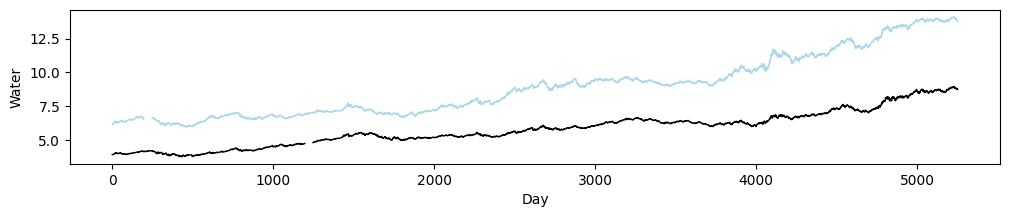

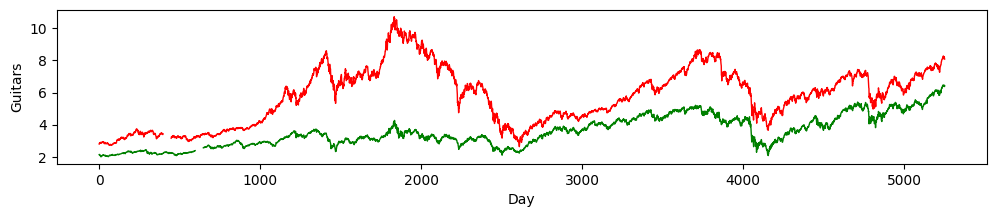

In [6]:
#combining some lines
#guitars:red, slingshots:green, stocks:blue, sugar:brown, water:black, tranquillity:purple, gurkow:lightblue

#water/gurkor
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["water"], label='Water', linewidth=1.0,color="black")
ax.plot(x_vals_full, df["gurkor"], label='Gurkor', linewidth=1.0, color="lightblue")
ax.set_xlabel("Day")
ax.set_ylabel("Water")
plt.show()

#guitars/slingshots
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df["guitars"], label='Guitars', linewidth=1.0,color="red")
ax.plot(x_vals_full, df["slingshots"], label='Slingshots', linewidth=1.0,color="green")

ax.set_xlabel("Day")
ax.set_ylabel("Guitars")
plt.show()

#tranquillity and sugar, no clear connection from basic price plots to any other?

### Trying log returns for connections

In [7]:
#plotting the log returns
#log returns, are often stationary, which is useful when a model requires it
df_log = df.copy()
    
for col in df.columns[2:]:
    df_log[col] = np.log(df[col]).diff()

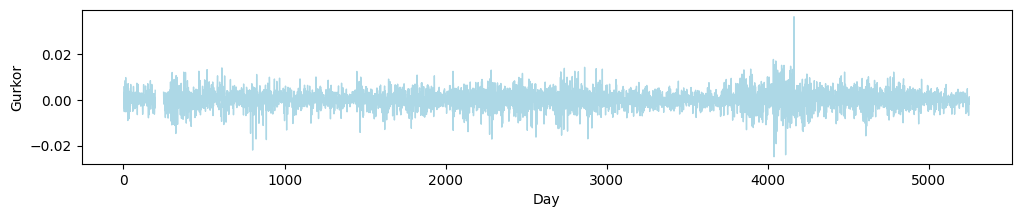

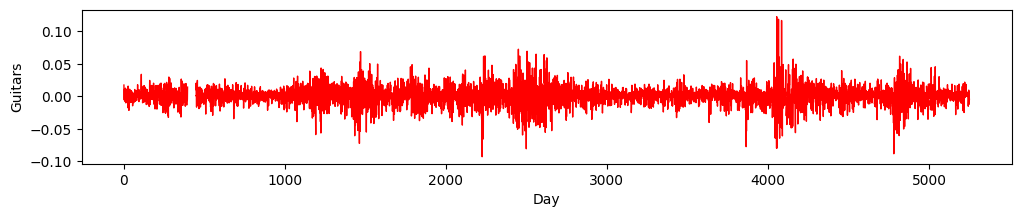

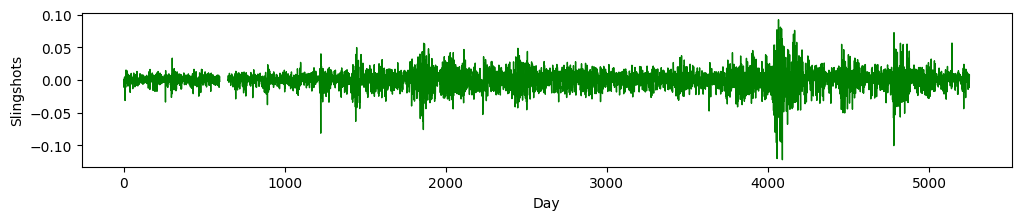

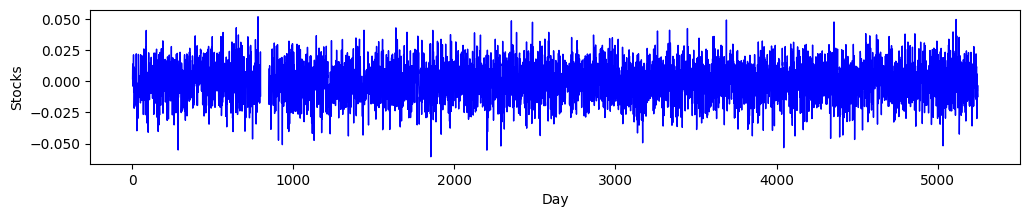

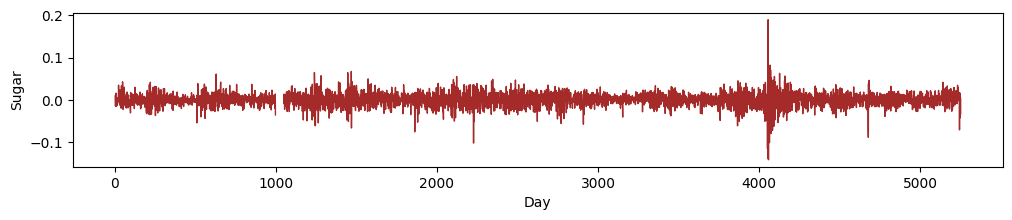

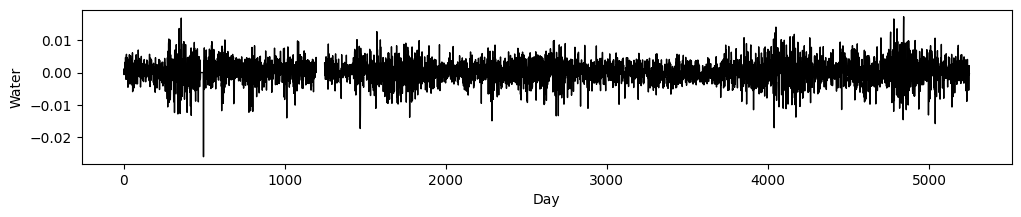

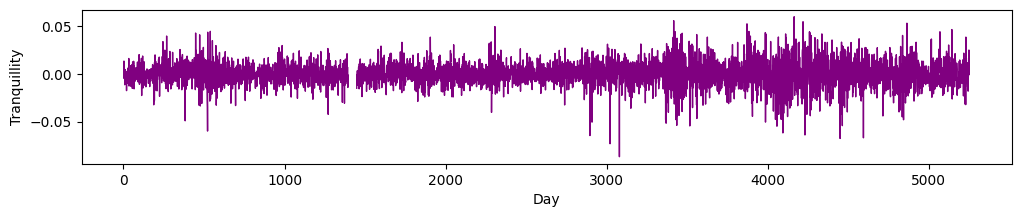

In [8]:
#guitars:red, slingshots:green, stocks:blue, sugar:brown, water:black, tranquillity:purple, gurkow:lightblue

#gurkor
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["gurkor"], label='Gurkor', linewidth=1.0,color="lightblue")
ax.set_xlabel("Day")
ax.set_ylabel("Gurkor")
plt.show()

#guitars
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["guitars"], label='Guitars', linewidth=1.0,color="red")
ax.set_xlabel("Day")
ax.set_ylabel("Guitars")
plt.show()

#slingshots
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["slingshots"], label='Slingshots', linewidth=1.0,color="green")
ax.set_xlabel("Day")
ax.set_ylabel("Slingshots")
plt.show()

#stocks
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["stocks"], label='Stocks', linewidth=1.0,color="blue")
ax.set_xlabel("Day")
ax.set_ylabel("Stocks")
plt.show()

#sugar
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["sugar"], label='Sugar', linewidth=1.0,color="brown")
ax.set_xlabel("Day")
ax.set_ylabel("Sugar")
plt.show()

#water
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["water"], label='Water', linewidth=1.0,color="black")
ax.set_xlabel("Day")
ax.set_ylabel("Water")
plt.show()

#tranquillity
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full, df_log["tranquillity"], label='Tranquillity', linewidth=1.0,color="purple")
ax.set_xlabel("Day")
ax.set_ylabel("Tranquillity")
plt.show()

### Checking the acf function over the log returns for any patterns

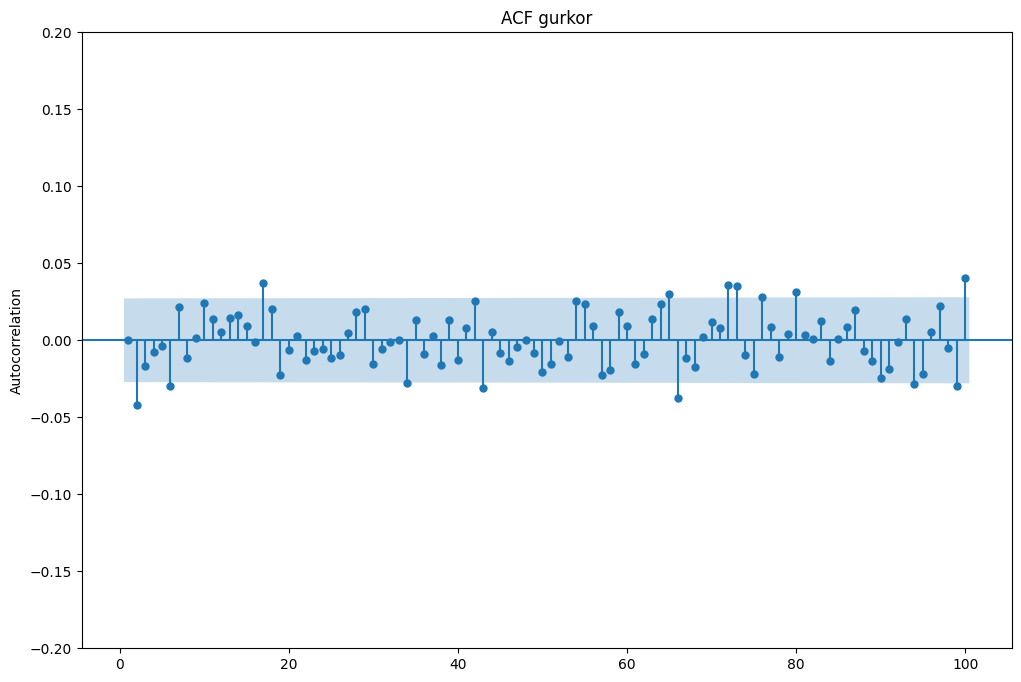

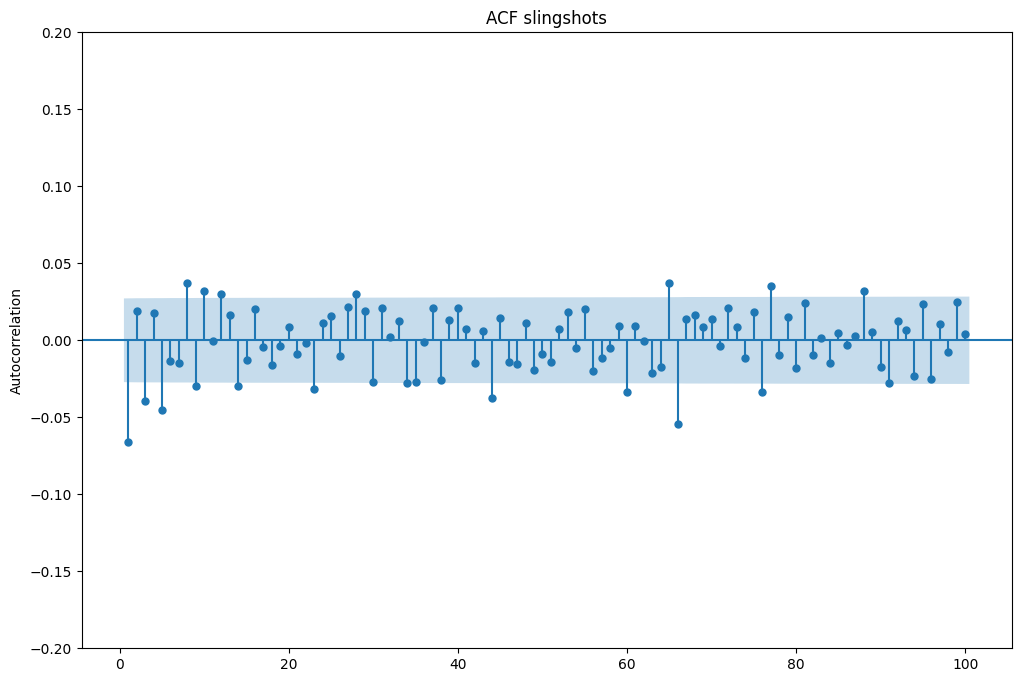

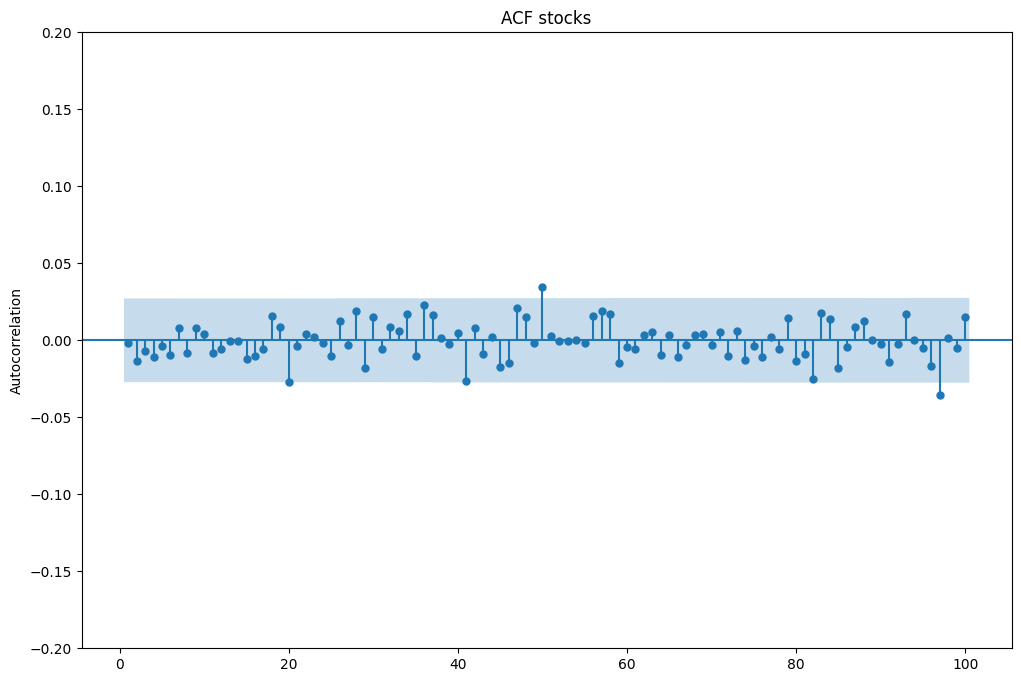

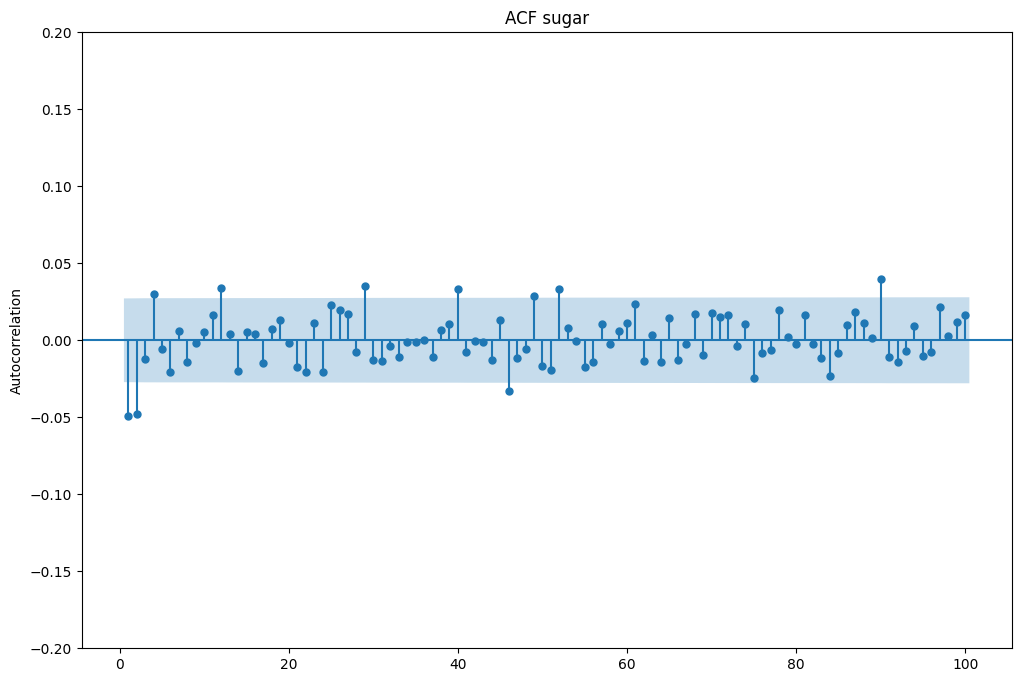

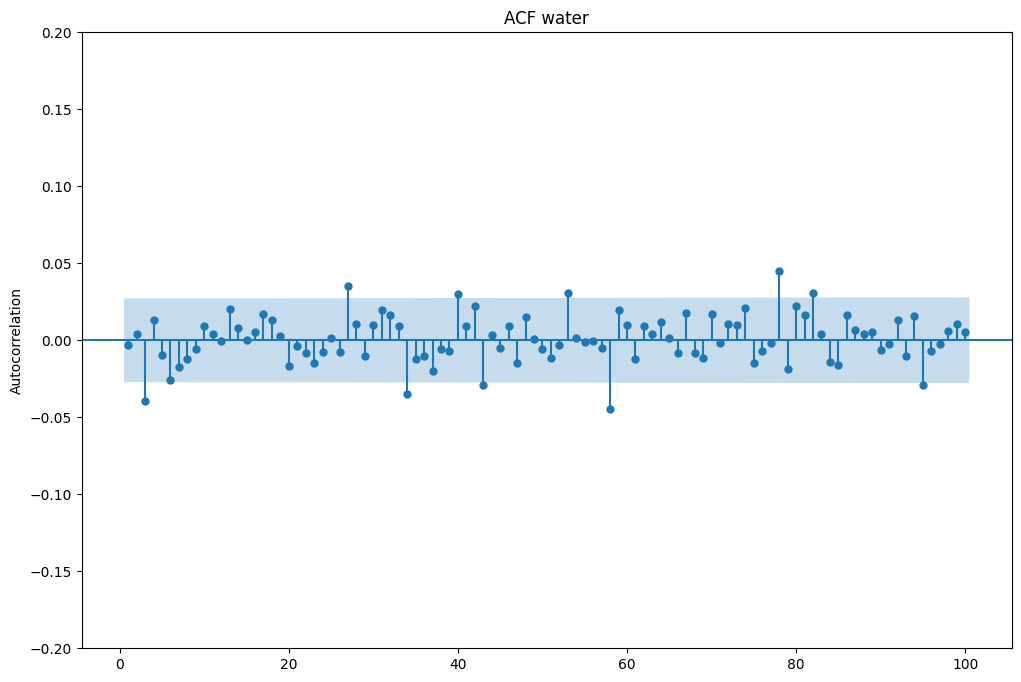

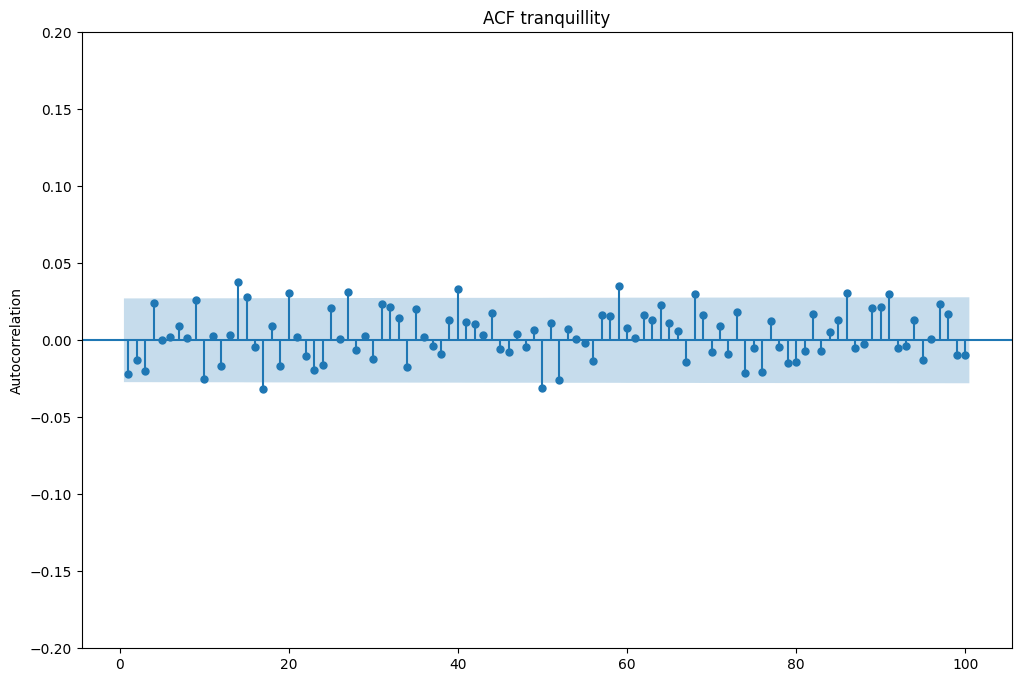

In [9]:


#guitars:red, slingshots:green, stocks:blue, sugar:brown, water:black, tranquillity:purple, gurkow:lightblue

fig, ax = plt.subplots(figsize=(12, 8))

plot_acf(df_log["gurkor"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF gurkor')
ax.set_ylim(-0.2, 0.2)
plt.show()


fig, ax = plt.subplots(figsize=(12, 8))
plot_acf(df_log["slingshots"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF slingshots')
ax.set_ylim(-0.2, 0.2)
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
plot_acf(df_log["stocks"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF stocks')
ax.set_ylim(-0.2, 0.2)
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
plot_acf(df_log["sugar"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF sugar')
ax.set_ylim(-0.2, 0.2)
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
plot_acf(df_log["water"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF water')
ax.set_ylim(-0.2, 0.2)
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))
plot_acf(df_log["tranquillity"].dropna(), lags=100, zero=False, ax=ax)
ax.set_ylabel('Autocorrelation')
ax.set_title('ACF tranquillity')
ax.set_ylim(-0.2, 0.2)
plt.show()



# Task 2

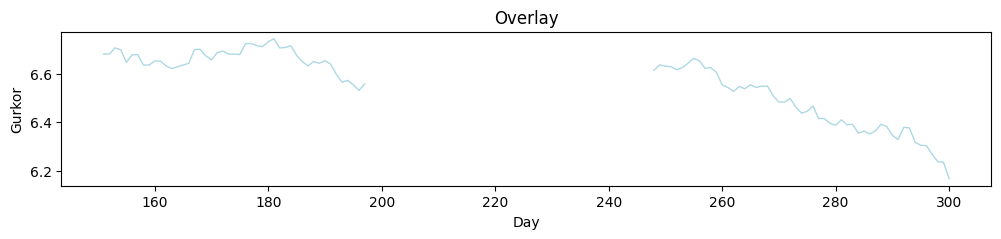

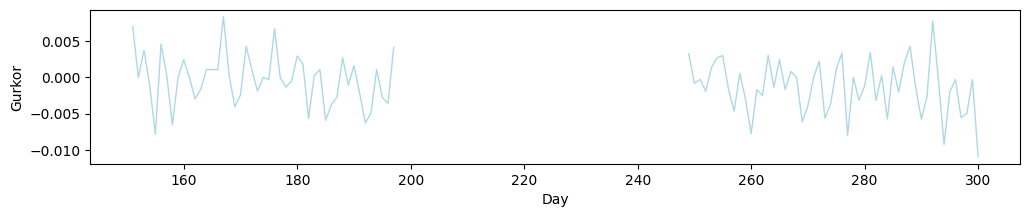

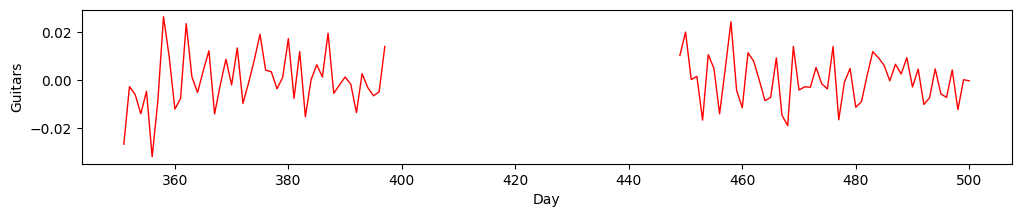

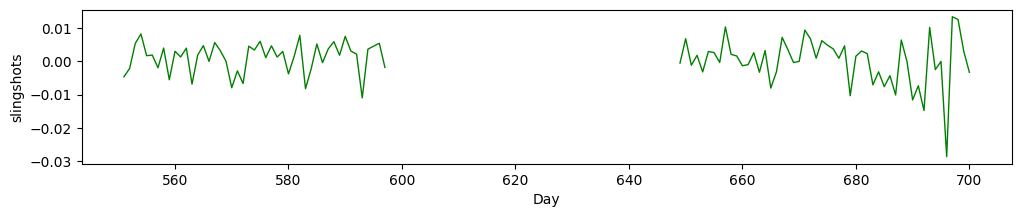

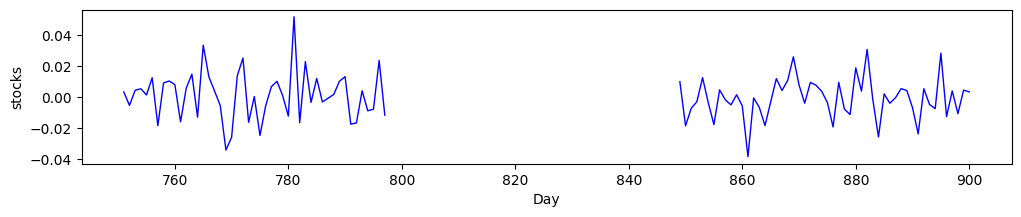

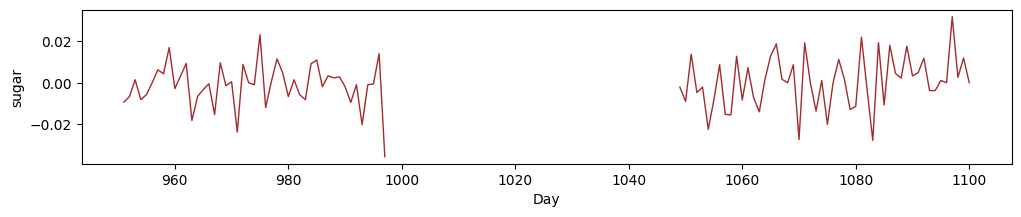

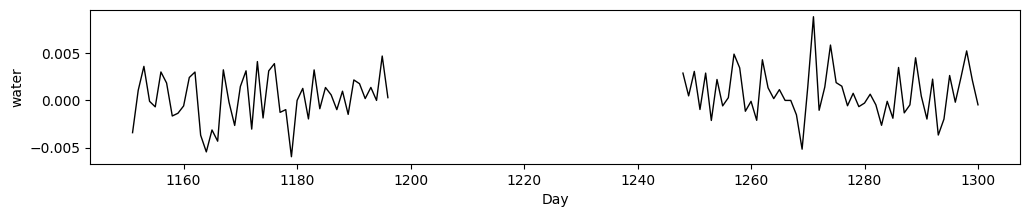

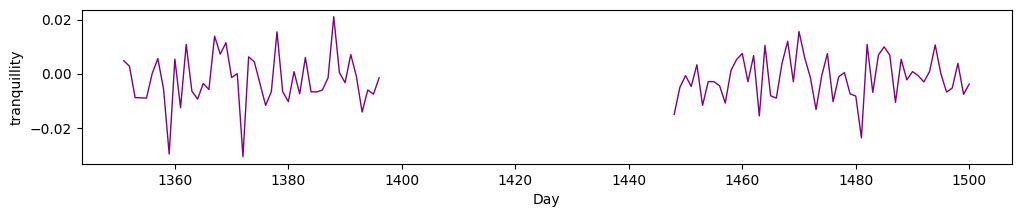

In [10]:
#guitars:red, slingshots:green, stocks:blue, sugar:brown, water:black, tranquillity:purple, gurkow:lightblue
#we can use this plot and compare to the interpolated values
days = df["day"].count()
x_vals_full = np.linspace(1, days, days)
nan_mask = np.isnan(df["gurkor"][0:300])

fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[150:300], df["gurkor"][150:300], label='Gurkor', linewidth=1.0, color="lightblue")

# Add title and labels
ax.set_title("Overlay")
ax.set_xlabel("Day")
ax.set_ylabel("Gurkor")

# Show the plot
plt.show()

#gurkor
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[150:300], df_log["gurkor"][150:300], label='Gurkor', linewidth=1.0,color="lightblue")
ax.set_xlabel("Day")
ax.set_ylabel("Gurkor")
plt.show()

#guitars
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[350:500], df_log["guitars"][350:500], label='Guitars', linewidth=1.0,color="red")
ax.set_xlabel("Day")
ax.set_ylabel("Guitars")
plt.show()

#slingshots
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[550:700], df_log["slingshots"][550:700], label='slingshots', linewidth=1.0,color="green")
ax.set_xlabel("Day")
ax.set_ylabel("slingshots")
plt.show()

#stocks
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[750:900], df_log["stocks"][750:900], label='stocks', linewidth=1.0,color="blue")
ax.set_xlabel("Day")
ax.set_ylabel("stocks")
plt.show()

#sugar
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[950:1100], df_log["sugar"][950:1100], label='sugar', linewidth=1.0,color="brown")
ax.set_xlabel("Day")
ax.set_ylabel("sugar")
plt.show()


#water
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[1150:1300], df_log["water"][1150:1300], label='water', linewidth=1.0,color="black")
ax.set_xlabel("Day")
ax.set_ylabel("water")
plt.show()


#tranquillity
fig, ax = plt.subplots(figsize=(12, 2))
ax.plot(x_vals_full[1350:1500], df_log["tranquillity"][1350:1500], label='tranquillity', linewidth=1.0,color="purple")
ax.set_xlabel("Day")
ax.set_ylabel("tranquillity")
plt.show()


/home/df/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


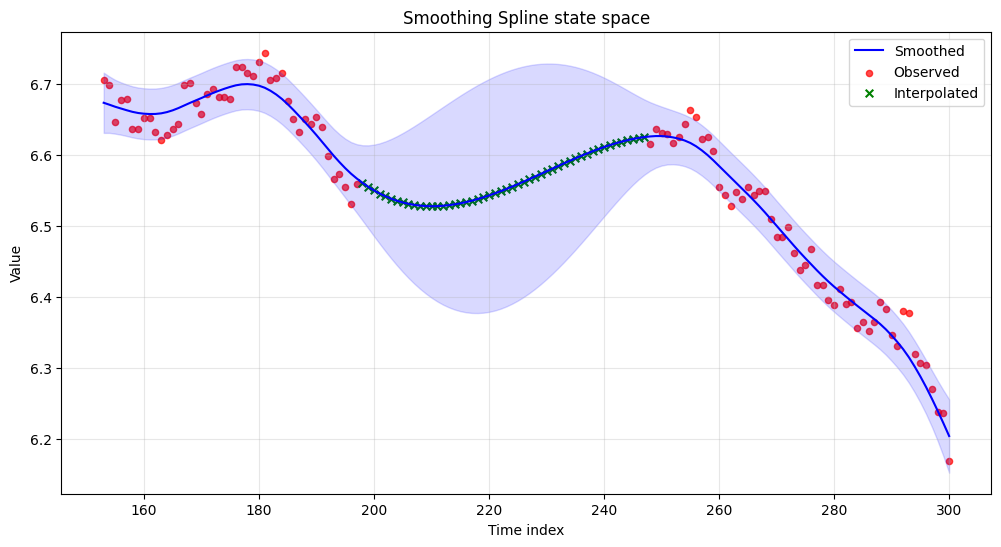

In [ ]:
from statsmodels.tsa.statespace.structural import UnobservedComponents
from numpy import ma
subset_gurkor = df["gurkor"][150:300]
gurkor_reg_m = ma.masked_array(subset_gurkor, mask=subset_gurkor.isna())


model = UnobservedComponents(
    subset_gurkor,
    level=True,
    trend=True,
    irregular=True,
    stochastic_trend=True,
    autoregressive = 1
)
res = model.fit(disp=False)
smoothed = res.smoothed_state[0]  # position estimates

plt.figure(figsize=(12, 6))

#first 2 points burn in
subset_gurkor = subset_gurkor[2:]
smoothed = smoothed[2:]

plt.plot(subset_gurkor.index, smoothed, color='blue', label='Smoothed')

# After fitting
smoothed_state_cov = res.smoother_results.smoothed_state_cov  # shape (k_states, k_states, nobs)
smoothed_state_var = smoothed_state_cov[0, 0, :]  # variance of the level (state 0)
smoothed_se = np.sqrt((smoothed_state_var)[2:])

# 95% intervals
from scipy.stats import norm
z = norm.ppf(0.975)
lower_smoothed = smoothed - z * smoothed_se
upper_smoothed = smoothed + z * smoothed_se
# Observed points

obs_mask = ~subset_gurkor.isna()
plt.scatter(subset_gurkor.index[obs_mask], subset_gurkor[obs_mask],
            color='red', s=20, alpha=0.7, label='Observed')

# Interpolated points
missing_mask = subset_gurkor.isna()
plt.scatter(subset_gurkor.index[missing_mask], smoothed[missing_mask],
            color='green', s=30, marker='x', label='Interpolated')

plt.fill_between(subset_gurkor.index, lower_smoothed, upper_smoothed, color='blue', alpha=0.15)


plt.legend()
plt.title('Smoothing Spline state space')
plt.xlabel('Time index')
plt.ylabel('Value')
plt.grid(alpha=0.3)
plt.show()

/home/df/miniconda3/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


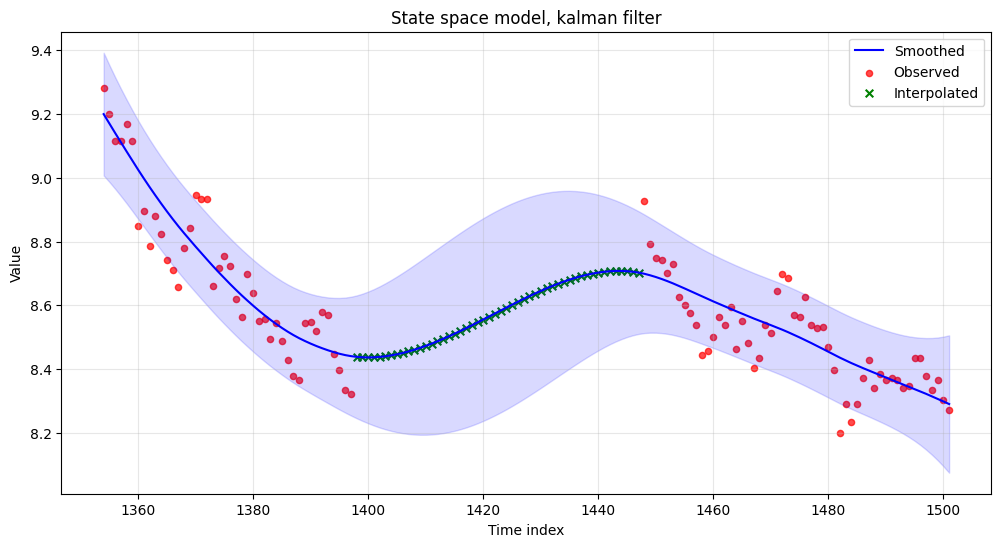

In [ ]:
from statsmodels.tsa.statespace.structural import UnobservedComponents
from numpy import ma

subset_gurkor = df["tranquillity"][1350:1500]
gurkor_reg_m = ma.masked_array(subset_gurkor, mask=subset_gurkor.isna())

#y_t = level+trend+irregular (white noise)+AR(1) component
model = UnobservedComponents(
    subset_gurkor,
    level=True,
    trend=True,
    irregular=True,
    stochastic_trend=True,
    autoregressive = 1
)

res = model.fit(disp=False)
smoothed = res.smoothed_state[0]  # position estimates
# --- Plot ---
plt.figure(figsize=(12, 6))

#first 2 points burn in
subset_gurkor = subset_gurkor[2:]
smoothed = smoothed[2:]

plt.plot(subset_gurkor.index, smoothed, color='blue', label='Smoothed')

# After fitting
smoothed_state_cov = res.smoother_results.smoothed_state_cov  # shape (k_states, k_states, nobs)
smoothed_state_var = smoothed_state_cov[0, 0, :]  # variance of the level (state 0)
smoothed_se = np.sqrt((smoothed_state_var)[2:])

# 95% intervals
from scipy.stats import norm
z = norm.ppf(0.975)
lower_smoothed = smoothed - z * smoothed_se
upper_smoothed = smoothed + z * smoothed_se
# Observed points

obs_mask = ~subset_gurkor.isna()
plt.scatter(subset_gurkor.index[obs_mask], subset_gurkor[obs_mask],
            color='red', s=20, alpha=0.7, label='Observed')

# Interpolated points
missing_mask = subset_gurkor.isna()
plt.scatter(subset_gurkor.index[missing_mask], smoothed[missing_mask],
            color='green', s=30, marker='x', label='Interpolated')

plt.fill_between(subset_gurkor.index, lower_smoothed, upper_smoothed, color='blue', alpha=0.15)


plt.legend()
plt.title('State space model, kalman filter')
plt.xlabel('Time index')
plt.ylabel('Value')
plt.grid(alpha=0.3)
plt.show()

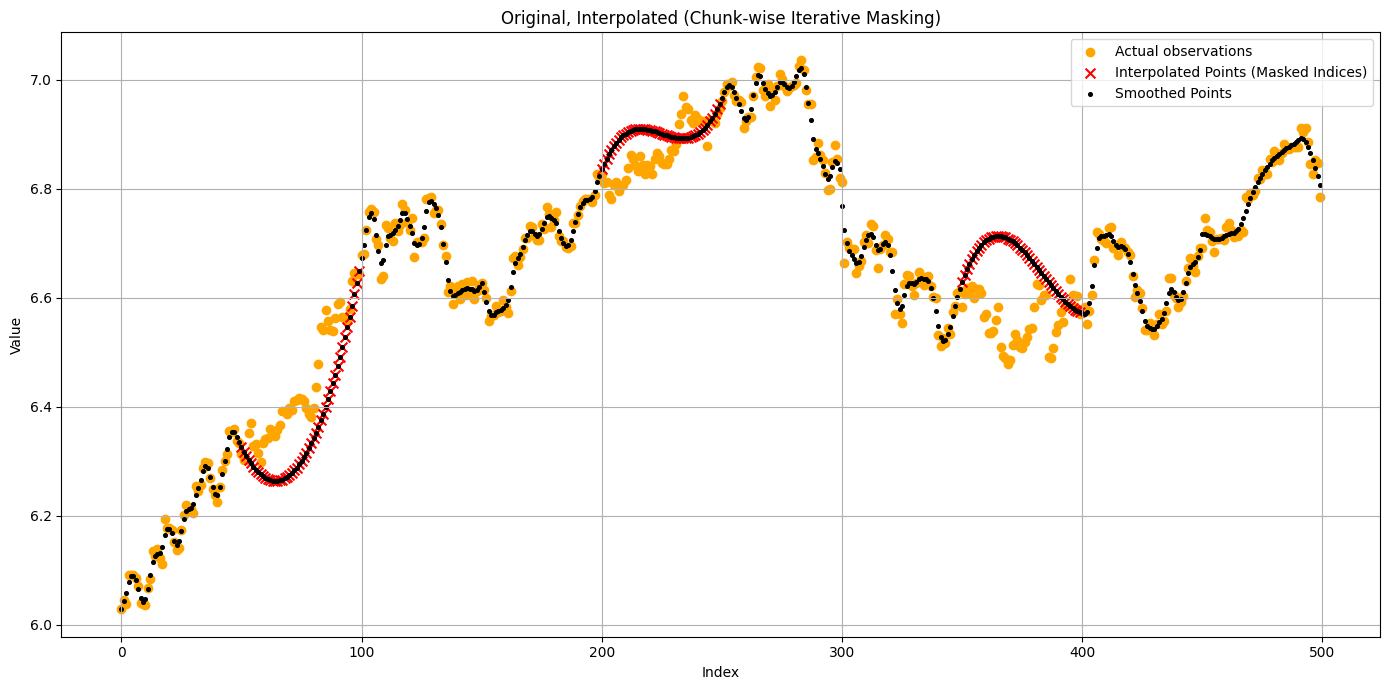

In [ ]:

x = np.arange(0,500,1)


# Extract interpolated values and indices from the DataFrame
interpolated_indices = interpolated_data["original_index"].values
interpolated_values = interpolated_data["interpolated_value"].values


# Step 6: Plot the results
plt.figure(figsize=(14, 7))
plt.scatter(x=x,y=subset_gurkor, label='Actual observations', color='orange', linestyle='-', linewidth=1)

# Plot interpolated points from your DataFrame (highlighted)
plt.scatter(
    x=interpolated_indices,
    y=interpolated_values,
    color='red',
    s=50,
    label='Interpolated Points (Masked Indices)',
    marker='x'
)

plt.scatter(x=x,
            y=smoothed_states,
            color='black', s=7, label='Smoothed Points')

plt.title('Original, Interpolated (Chunk-wise Iterative Masking)')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("iterative_chunkwise_gurkor_interpolation_plot.png", dpi=200)
plt.show()